# What Vietnamese consumer loans really cost

*An analysis of the Vay Đúng dataset: 82 consumer loan products from 20 lenders licensed by the State Bank of Vietnam, collected in November 2026.*

**Questions**
1. How much does a flat-rate quote (*lãi phẳng*) understate the real yearly rate?
2. How far apart are banks and finance companies once every quote is converted to the same measure?
3. What does a typical loan cost in đồng, and what income does it need?
4. How reliable is the published data?

**Method.** Each product is converted to a **real yearly rate**: the internal rate of return (IRR) of the borrower's cash flows × 12, which is the "real APR" the app shows. The arithmetic is imported from `scripts/check/finance_check.py`, the independent Python check that matched the app's engine to the đồng on 1,628 cases.

**Scope.** The figures include the interest rate and fixed monthly fees. They leave out one-off fees and insurance, which are rarely published in full. So every real rate here is a **lower bound**: the true cost can only be higher. This is a student project, not financial advice.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from decimal import Decimal as D
from loans import load_offers, loan, ranked_table

pd.set_option("display.width", 200)
offers, as_of = load_offers()
print(f"{len(offers)} products, data as of {as_of}")

# Chart style: thin marks, quiet axes, text in ink colours rather than series colours.
INK, INK2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
COLOR = {"Bank": "#2a78d6", "Finance company": "#eb6834"}
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "text.color": INK, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False, "font.size": 10, "figure.dpi": 110,
})

82 products, data as of 2026-11-05


## 0. Sanity check against the app

FE Credit advertises 1.41% a month, flat. For 10 million đồng over 12 months, the app shows a real APR of **29.89%** and a total repaid of **11,692,000 đ**. The same function must give the same answer here.

In [2]:
fe = loan(10_000_000, 12, D("0.0141"), "flat")
print(f"real APR {fe['aprNominal']*100:.2f}%  total repaid {fe['totalRepaid']:,} đ")
assert round(fe["aprNominal"] * 100, 2) == 29.89 and fe["totalRepaid"] == 11_692_000

real APR 29.89%  total repaid 11,692,000 đ


## 1. The flat-rate illusion

A flat rate charges interest on the **original** amount every month, even as the balance falls. "1.5% a month" sounds like 18% a year, but on average the borrower holds only about half the money. So the real rate is far higher. The chart shows the gap for every term from 3 to 60 months.

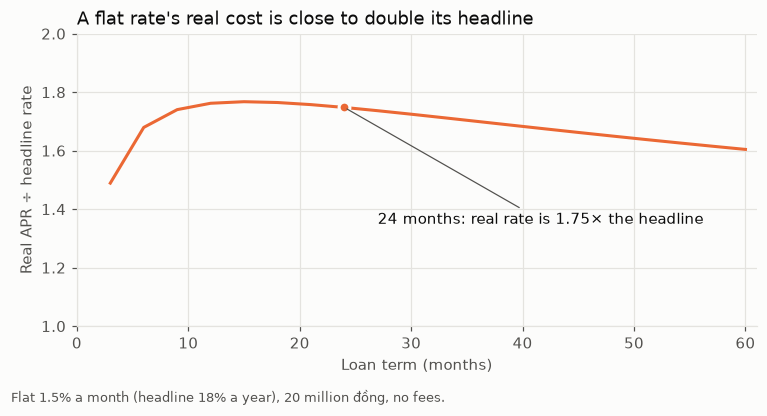

 term  real ÷ headline
    6             1.68
   12             1.76
   24             1.75
   36             1.70
   48             1.65
   60             1.60


In [3]:
terms = list(range(3, 61, 3))
ratio = [loan(20_000_000, n, D("0.015"), "flat")["aprNominal"] * 100 / 18 for n in terms]
r24 = ratio[terms.index(24)]

fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(terms, ratio, color=COLOR["Finance company"], linewidth=2)
ax.scatter([24], [r24], s=50, color=COLOR["Finance company"], zorder=3, edgecolor=SURFACE, linewidth=2)
ax.annotate(f"24 months: real rate is {r24:.2f}× the headline", (24, r24),
            xytext=(27, 1.35), color=INK, arrowprops=dict(arrowstyle="-", color=INK2, lw=0.8))
ax.set(xlabel="Loan term (months)", ylabel="Real APR ÷ headline rate", ylim=(1, 2), xlim=(0, 61))
ax.set_title("A flat rate's real cost is close to double its headline", loc="left", fontsize=12, color=INK)
fig.text(0.01, -0.03, "Flat 1.5% a month (headline 18% a year), 20 million đồng, no fees.", color=INK2, fontsize=8.5)
fig.tight_layout(); fig.savefig("figures/01-flat-illusion.png", bbox_inches="tight"); plt.show()

print(pd.DataFrame({"term": terms, "real ÷ headline": ratio}).query("term in [6, 12, 24, 36, 48, 60]").round(2).to_string(index=False))

### The same gap in the real products

This shows how the gap plays out across the flat-quoted products in the dataset. It uses each lender's **highest** published rate, which is what the app ranks on, because borrowers don't know what rate they'll be offered. Each product is costed at 20 million đồng over 24 months, or the nearest amount and term it allows, with its monthly fees included.

Products that publish only a floor ("from X%") have no known ceiling, so they're left out from here on.

67 ranked products, 52 with a published ceiling


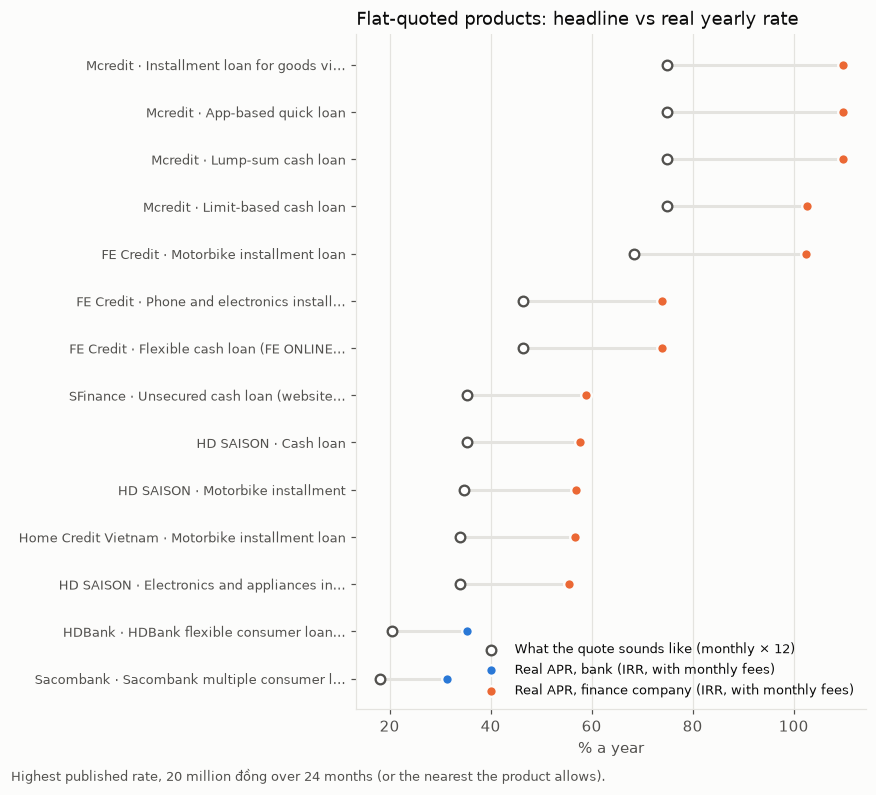

14 flat-quoted products. Real ÷ headline: median 1.61×, range 1.37–1.75×


,lender,product,quoted_max,period,term,headline_max_yearly,apr_max,real ÷ headline
41,Sacombank,Sacombank multiple consumer loans on SACOMBANK...,1.50,monthly,24,18.00,31.46,1.75
8,HDBank,HDBank flexible consumer loan (credit-card hol...,1.70,monthly,24,20.40,35.28,1.73
11,HD SAISON,Electronics and appliances installment,2.82,monthly,24,33.84,55.53,1.64
14,Home Credit Vietnam,Motorbike installment loan,33.94,yearly,24,33.94,56.62,1.67
10,HD SAISON,Motorbike installment,2.90,monthly,24,34.80,56.91,1.64
9,HD SAISON,Cash loan,2.94,monthly,24,35.28,57.60,1.63
42,SFinance,Unsecured cash loan (website application),35.40,yearly,24,35.40,58.80,1.66
3,FE Credit,Flexible cash loan (FE ONLINE app),3.86,monthly,24,46.32,73.93,1.60
5,FE Credit,Phone and electronics installment loan,3.86,monthly,24,46.32,73.93,1.60
4,FE Credit,Motorbike installment loan,5.70,monthly,24,68.40,102.44,1.50


In [4]:
all_ranked = ranked_table(amount=20_000_000, term=24)
df = all_ranked[~all_ranked.floor_only].copy()
print(f"{len(all_ranked)} ranked products, {len(df)} with a published ceiling")
flat = df[df.basis == "flat"].copy()
flat["label"] = [f"{l} · {p if len(p) <= 30 else p[:29].rstrip() + '…'}" for l, p in zip(flat.lender, flat["product"])]
flat = flat.sort_values("apr_max")

fig, ax = plt.subplots(figsize=(8, 0.42 * len(flat) + 1.2))
y = range(len(flat))
ax.hlines(y, flat.headline_max_yearly, flat.apr_max, color=GRID, linewidth=2)
ax.scatter(flat.headline_max_yearly, y, s=40, color="#ffffff", edgecolor=INK2, linewidth=1.5, zorder=3, label="What the quote sounds like (monthly × 12)")
for kind in COLOR:
    pos = [i for i, t in enumerate(flat.lender_type) if t == kind]
    ax.scatter(flat.apr_max.iloc[pos], pos, s=48, color=COLOR[kind], edgecolor=SURFACE, linewidth=1.5, zorder=3, label=f"Real APR, {kind.lower()} (IRR, with monthly fees)")
ax.set_yticks(list(y), flat.label, fontsize=8.5)
ax.set_xlabel("% a year")
ax.grid(axis="y", visible=False)
ax.legend(loc="lower right", frameon=False, fontsize=8.5)
ax.set_title("Flat-quoted products: headline vs real yearly rate", loc="left", fontsize=12, color=INK)
fig.text(0.01, -0.01, "Highest published rate, 20 million đồng over 24 months (or the nearest the product allows).", color=INK2, fontsize=8.5)
fig.tight_layout(); fig.savefig("figures/02-flat-products.png", bbox_inches="tight"); plt.show()

flat["real ÷ headline"] = flat.apr_max / flat.headline_max_yearly
print(f"{len(flat)} flat-quoted products. Real ÷ headline: median {flat['real ÷ headline'].median():.2f}×, "
      f"range {flat['real ÷ headline'].min():.2f}–{flat['real ÷ headline'].max():.2f}×")
flat[["lender", "product", "quoted_max", "period", "term", "headline_max_yearly", "apr_max", "real ÷ headline"]].round(2)

**Reading it.** Every flat quote understates the cost, with the real rate 1.4–1.75× the headline. The multiple is lower for very high rates (Mcredit's 6.25% a month comes out about 1.4×) and close to 1.75× for ordinary ones. Monthly fees push it up further. A borrower comparing "1.7% a month flat" with "24% a year reducing" will usually pick the flat one, and usually pay more. That's why the app converts every quote with an IRR rather than a rule of thumb.

## 2. Banks vs finance companies, on the same measure

Each dot is one product the app ranks, at its highest published rate, costed the same way.

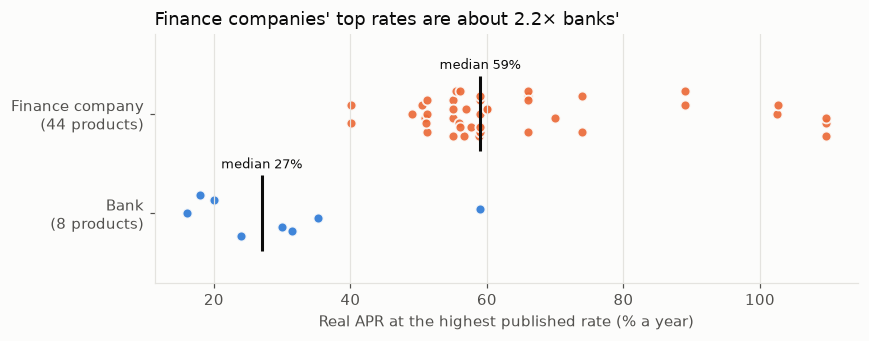

,products,lenders,median_real_apr_max,highest_real_apr,median_cost_20m_24m
lender_type,,,,,
Bank,8,7,27.0,59.0,6108144.0
Finance company,44,12,59.0,109.7,14504588.0


In [5]:
fig, ax = plt.subplots(figsize=(8, 3.2))
for i, (kind, g) in enumerate(df.groupby("lender_type")):
    jitter = [((j * 37) % 11 - 5) / 22 for j in range(len(g))]   # fixed spread so dots don't hide each other
    ax.scatter(g.apr_max, [i + k for k in jitter], s=42, color=COLOR[kind], alpha=0.9, edgecolor=SURFACE, linewidth=1.2)
    med = g.apr_max.median()
    ax.vlines(med, i - 0.38, i + 0.38, color=INK, linewidth=2)
    ax.text(med, i + 0.45, f"median {med:.0f}%", ha="center", color=INK, fontsize=8.5)
ax.set_yticks([0, 1], [f"{k}\n({n} products)" for k, n in df.lender_type.value_counts().sort_index().items()])
ax.set_ylim(-0.7, 1.8)
ax.set_xlabel("Real APR at the highest published rate (% a year)")
ax.grid(axis="y", visible=False)
meds = df.groupby("lender_type").apr_max.median()
ax.set_title(f"Finance companies' top rates are about {meds['Finance company'] / meds['Bank']:.1f}× banks'", loc="left", fontsize=12, color=INK)
fig.tight_layout(); fig.savefig("figures/03-bank-vs-finance.png", bbox_inches="tight"); plt.show()

summary = df.groupby("lender_type").agg(products=("key", "size"), lenders=("lender", "nunique"),
    median_real_apr_max=("apr_max", "median"), highest_real_apr=("apr_max", "max"),
    median_cost_20m_24m=("total_cost_max", "median"))
summary.round(1)

**Reading it.** At their published ceilings, most bank products sit between about 15% and 35% a year, with one bank publishing a ceiling of 59%. Most finance-company products top out between 45% and 70%, and a few go above 100%. Two caveats:
- Few bank products are here, because most banks don't publish a top rate, so the bank group is small.
- A ceiling is the worst case. Many borrowers are offered less, but lenders don't say who.

## 3. What a 20 million đồng loan costs, in đồng

This section looks at the money: the extra paid on top of 20 million over 24 months, and the monthly income needed to keep this one payment under the app's 40% debt-to-income guideline.

In [6]:
DTI = 0.40
money = df.assign(
    extra_cost_million=df.total_cost_max / 1e6,
    payment_thousand=df.payment_max / 1e3,
    income_needed_million=df.payment_max / DTI / 1e6,
)
same = money[(money.amount == 20_000_000) & (money.term == 24)]
print(f"{len(same)} products allow exactly 20 million over 24 months.")
same.groupby("lender_type")[["extra_cost_million", "payment_thousand", "income_needed_million"]].describe(percentiles=[0.5]).round(1).T

49 products allow exactly 20 million over 24 months.


lender_type                    Bank  Finance company
extra_cost_million    count     8.0             41.0
                      mean      6.7             15.9
                      std       3.5              5.1
                      min       3.5              9.4
                      50%       6.1             14.5
                      max      14.5             30.0
payment_thousand      count     8.0             41.0
                      mean   1114.5           1493.8
                      std     147.7            213.9
                      min     979.3           1225.0
                      50%    1087.8           1437.7
                      max    1437.7           2083.3
income_needed_million count     8.0             41.0
                      mean      2.8              3.7
                      std       0.4              0.5
                      min       2.4              3.1
                      50%       2.7              3.6
                      max       3.6              5.2

In [7]:
cheapest, dearest = same.nsmallest(1, "total_cost_max").iloc[0], same.nlargest(1, "total_cost_max").iloc[0]
for tag, r in [("Cheapest", cheapest), ("Most expensive", dearest)]:
    print(f"{tag}: {r.lender} – {r['product']} (rate source: {r.source_type}): pay {r.payment_max:,.0f} đ a month, "
          f"{r.total_cost_max/1e6:.1f} million on top of the 20 million, needs income ≥ {r.payment_max/DTI/1e6:.1f} million a month")
print(f"\nSame amount, same term: the most expensive costs {dearest.total_cost_max/cheapest.total_cost_max:.1f}× as much as the cheapest.")

Cheapest: Techcombank – Unsecured instalment consumer loan (Techcombank Mobile) (rate source: aggregator): pay 979,268 đ a month, 3.5 million on top of the 20 million, needs income ≥ 2.4 million a month
Most expensive: Mcredit – Lump-sum cash loan (rate source: official): pay 2,083,341 đ a month, 30.0 million on top of the 20 million, needs income ≥ 5.2 million a month

Same amount, same term: the most expensive costs 8.6× as much as the cheapest.


**Reading it.** For the same 20 million over two years, the extra cost at the ceiling runs from about 3.5 million to 30 million đồng. (The cheapest figure comes from a comparison site, so treat it as indicative.) For the target user, a young salaried worker earning 10–20 million a month, choosing the right product is worth more than a month's salary. That spread is the reason the product exists.

## 4. How reliable is the data?

The quality of the inputs belongs next to the findings.

In [8]:
quality = pd.DataFrame({
    "products": [len(offers)],
    "with a usable rate": [sum(o["rate"] is not None for o in offers)],
    "ranked by the app": [len(all_ranked)],
    "ranked, rate from the lender itself": [(all_ranked.source_type == "official").sum()],
    "ranked, rate from a comparison site / press": [(all_ranked.source_type != "official").sum()],
    'ranked, only a floor ("from X%") published': [all_ranked.floor_only.sum()],
    "fees fully published": [sum(o["feesCompleteness"] == "complete" for o in offers)],
    "insurance terms unknown": [sum(o["insuranceCompleteness"] == "unknown" for o in offers)],
    "confidence: medium": [sum(o["confidence"] == "medium" for o in offers)],
    "confidence: low": [sum(o["confidence"] == "low" for o in offers)],
}).T.rename(columns={0: "count"})
quality

,count
products,82
with a usable rate,68
ranked by the app,67
"ranked, rate from the lender itself",60
"ranked, rate from a comparison site / press",7
"ranked, only a floor (""from X%"") published",15
fees fully published,0
insurance terms unknown,43
confidence: medium,16
confidence: low,66


**Reading it.**
- Most rates come from the lenders' own pages, but **no product publishes its fees completely**, and insurance terms are unknown for about half.
- Most products are rated *low* confidence, because lenders publish wide company-wide ranges rather than product prices.

The lack of transparency the app tries to fix also limits what any comparison can say. That's why the app shows "chưa rõ" (unknown) rather than guessing.

## Findings

1. **Flat quotes understate the real rate by 40–75%.** Across the flat-quoted products, the real APR is 1.4–1.75× the headline. For a typical 1.5% a month quote it stays between 1.6× and 1.8× at every term from 6 to 60 months.
2. **Lender type is the biggest divide.** At published ceilings, finance companies (median 59% a year) cost about twice as much as banks (median 27%, from only 8 bank products).
3. **The choice is worth millions.** For the same 20 million over 24 months, the extra cost at the ceiling ranges from about 3.5 to 30 million đồng.
4. **Disclosure is incomplete.** No product publishes all its fees, so every figure here is a lower bound.

**Limitations**
- The rates are published ranges, not personal offers.
- One-off fees and insurance are left out.
- The bank sample is small.
- Duplicate listings of one rate card (one per channel or product) are kept as published.
- The data is a November 2026 snapshot.

**What I'd do next**
- Collect real offers, with consent, in user interviews to see where in the published range people actually land.
- Track the gap between headline and real rates over time as an indicator of disclosure quality.